# Assignment 3: Probabilistic PCA

*Course:* Machine Learning: Advanced Techniques

*Authors:* Eric Volkmann / Klemens Hauzenberg / Bertalan Toppantó / Markus Holzleitner

*Copyright statement:* This material, no matter whether in printed or electronic form, may be used for personal and non-commercial educational use only. Any reproduction of this manuscript, no matter whether as a whole or in parts, no matter whether in printed or in electronic form, requires explicit prior acceptance of the authors.

## Organisation and notation

Derivation tasks are answered in the markdown cells marked *YOUR SOLUTION HERE* (LaTeX is supported), programming tasks in the code cells marked *YOUR SOLUTION HERE*. Do not delete or reorder cells. Required packages: `numpy`, `matplotlib`, `scikit-learn`, `torch` (CPU is sufficient), `SimpleITK` and `pydicom` (Exercise 4 only, see the install notes there). The `images` folder of Exercise 4 has to be located next to this notebook. The training cell of Exercise 4 runs for about 2–3 minutes on a laptop CPU.

Throughout, we use the notation of the lecture slides on probabilistic PCA (slide numbers refer to this slide set):

* **Observed and latent variables:** $\mathbf{x} \in \mathbb{R}^d$ is an observation, $\mathbf{z} \in \mathbb{R}^m$ the corresponding latent variable, $m < d$. The data set consists of $l$ i.i.d. observations, collected in $\mathbf{X} = (\mathbf{x}_1, \ldots, \mathbf{x}_l) \in \mathbb{R}^{d \times l}$ (one observation per **column**).
* **Probabilistic PCA model** (slide 27): $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ and $\mathbf{x} \mid \mathbf{z} \sim \mathcal{N}(\mathbf{W}\mathbf{z} + \boldsymbol{\mu}, \sigma^2 \mathbf{I})$, or equivalently $\mathbf{x} = \mathbf{W}\mathbf{z} + \boldsymbol{\mu} + \boldsymbol{\varepsilon}$ with $\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{I})$ independent of $\mathbf{z}$. The parameters are $\mathbf{W} \in \mathbb{R}^{d \times m}$, $\boldsymbol{\mu} \in \mathbb{R}^d$ and $\sigma^2 > 0$; $\mathbf{I}$ denotes an identity matrix of the appropriate size. The original paper is [Tipping and Bishop (1999)](https://www.cs.columbia.edu/~blei/seminar/2020-representation/readings/TippingBishop1999.pdf).
* **Marginal distribution** (slide 31): $p(\mathbf{x} \mid \mathbf{W}, \boldsymbol{\mu}, \sigma^2) = \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}, \mathbf{C})$ with $\mathbf{C} = \mathbf{W}\mathbf{W}^\top + \sigma^2 \mathbf{I} \in \mathbb{R}^{d \times d}$. We write $\mathcal{N}(\mathbf{x} \mid \mathbf{a}, \boldsymbol{\Sigma})$ for the density of a Gaussian with mean $\mathbf{a}$ and covariance matrix $\boldsymbol{\Sigma}$ evaluated at $\mathbf{x}$.
* **Log-likelihood** (slide 37): $\log p(\mathbf{X} \mid \mathbf{W}, \boldsymbol{\mu}, \sigma^2) = \sum_{i=1}^l \log p(\mathbf{x}_i \mid \mathbf{W}, \boldsymbol{\mu}, \sigma^2)$.
* **Posterior over the latent variable** (slide 35): $p(\mathbf{z} \mid \mathbf{x}) = \mathcal{N}\big(\mathbf{z} \mid \mathbf{M}^{-1}\mathbf{W}^\top(\mathbf{x} - \boldsymbol{\mu}),\, \sigma^2 \mathbf{M}^{-1}\big)$ with $\mathbf{M} = \mathbf{W}^\top\mathbf{W} + \sigma^2 \mathbf{I} \in \mathbb{R}^{m \times m}$.
* **Sample mean and empirical covariance:** $\hat{\boldsymbol{\mu}} = \frac{1}{l}\sum_{i=1}^l \mathbf{x}_i$ and $\mathbf{S} = \frac{1}{l}\sum_{i=1}^l (\mathbf{x}_i - \hat{\boldsymbol{\mu}})(\mathbf{x}_i - \hat{\boldsymbol{\mu}})^\top$ (slide 20, for centered data). $\mathbf{S}$ has eigenvalues $\lambda_1 \geq \cdots \geq \lambda_d \geq 0$ with orthonormal eigenvectors $\mathbf{u}_1, \ldots, \mathbf{u}_d$; we write $\mathbf{U}_m = (\mathbf{u}_1, \ldots, \mathbf{u}_m) \in \mathbb{R}^{d \times m}$ and $\mathbf{L}_m = \operatorname{diag}(\lambda_1, \ldots, \lambda_m)$ (slide 38), and $\mathbf{U} = (\mathbf{u}_1, \ldots, \mathbf{u}_d)$, $\mathbf{L} = \operatorname{diag}(\lambda_1, \ldots, \lambda_d)$ for the full eigenvalue decomposition $\mathbf{S} = \mathbf{U}\mathbf{L}\mathbf{U}^\top$.
* **Maximum likelihood solution** (theorem on slide 38): $\hat{\boldsymbol{\mu}} = \frac{1}{l}\sum_{i=1}^l \mathbf{x}_i$, $\;\hat\sigma^2 = \frac{1}{d-m}\sum_{j=m+1}^d \lambda_j$, $\;\hat{\mathbf{W}} = \mathbf{U}_m (\mathbf{L}_m - \hat\sigma^2 \mathbf{I})^{1/2} \mathbf{R}$ with an arbitrary orthogonal matrix $\mathbf{R} \in \mathbb{R}^{m \times m}$.
* $\log$ is the natural logarithm, $|\mathbf{A}|$ the determinant and $\operatorname{tr}(\mathbf{A})$ the trace of a square matrix $\mathbf{A}$.
* **Code convention:** in the code cells, data matrices are stored with one sample per **row**, i.e. the array `X` of shape `(l, d)` corresponds to $\mathbf{X}^\top$ of the lecture notation. The sample size, the data dimension and the latent dimension are called `l`, `d` and `m` as in the lecture.

## Theory / Derivations

### Exercise 1: Moment Generating Functions (MGF) (2 pts)

#### 1a) MGF of $\mathbf{W}\boldsymbol{\xi} + \boldsymbol{\mu}$ (1 pt)

The moment generating function (MGF) of a random vector $\boldsymbol{\xi} \in \mathbb{R}^m$ is defined as
\begin{align*}
    M_{\boldsymbol{\xi}}(\mathbf{t}) = \mathbb{E}\big[\exp(\mathbf{t}^\top \boldsymbol{\xi})\big], \qquad \mathbf{t} \in \mathbb{R}^m .
\end{align*}
Let $\mathbf{W} \in \mathbb{R}^{d \times m}$ and $\boldsymbol{\mu} \in \mathbb{R}^d$ be fixed (non-random). Show that the MGF of the random vector $\mathbf{W}\boldsymbol{\xi} + \boldsymbol{\mu} \in \mathbb{R}^d$ is
\begin{align*}
    M_{\mathbf{W}\boldsymbol{\xi} + \boldsymbol{\mu}}(\mathbf{t}) = \exp(\mathbf{t}^\top \boldsymbol{\mu})\, M_{\boldsymbol{\xi}}(\mathbf{W}^\top \mathbf{t}), \qquad \mathbf{t} \in \mathbb{R}^d .
\end{align*}

########## YOUR SOLUTION HERE ##########

Let $\mathbf t\in\mathbb R^d$. Since $\mathbf W$ and $\boldsymbol\mu$ are deterministic, the definition gives
$$
\begin{aligned}
M_{\mathbf W\boldsymbol\xi+\boldsymbol\mu}(\mathbf t)
&=\mathbb E[\exp(\mathbf t^\top(\mathbf W\boldsymbol\xi+\boldsymbol\mu))]\\
&=\mathbb E[\exp(\mathbf t^\top\boldsymbol\mu)\exp(\mathbf t^\top\mathbf W\boldsymbol\xi)]\\
&=\exp(\mathbf t^\top\boldsymbol\mu)\mathbb E[\exp((\mathbf W^\top\mathbf t)^\top\boldsymbol\xi)]\\
&=\boxed{\exp(\mathbf t^\top\boldsymbol\mu)M_{\boldsymbol\xi}(\mathbf W^\top\mathbf t)}.
\end{aligned}
$$
Here $\mathbf W^\top\mathbf t\in\mathbb R^m$, as required for the argument of $M_{\boldsymbol\xi}$. The equality holds wherever the MGF is finite (and also as an equality of nonnegative extended expectations).

#### 1b) Linear combination of Gaussians (1 pt)

If $\boldsymbol{\xi} \sim \mathcal{N}(\mathbf{a}, \boldsymbol{\Sigma})$ is a Gaussian random vector with mean $\mathbf{a}$ and covariance matrix $\boldsymbol{\Sigma}$, then its MGF is given by
\begin{align*}
    M_{\boldsymbol{\xi}}(\mathbf{t}) = \exp\big(\mathbf{t}^\top \mathbf{a} + \tfrac12\, \mathbf{t}^\top \boldsymbol{\Sigma}\, \mathbf{t}\big).
\end{align*}
Use this fact and the result of 1a) to show that in the pPCA model $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$, $\mathbf{x} \mid \mathbf{z} \sim \mathcal{N}(\mathbf{W}\mathbf{z} + \boldsymbol{\mu}, \sigma^2 \mathbf{I})$ the marginal distribution of $\mathbf{x}$ is
\begin{align*}
    p(\mathbf{x} \mid \mathbf{W}, \boldsymbol{\mu}, \sigma^2) = \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu},\, \mathbf{W}\mathbf{W}^\top + \sigma^2 \mathbf{I})
\end{align*}
(slide 31). You can assume that $\mathbf{z}$ and $\boldsymbol{\varepsilon}$ are independent.

*Hint: argue that $\mathbf{x}$ can be written as $\mathbf{x} = \mathbf{W}\mathbf{z} + \boldsymbol{\mu} + \boldsymbol{\varepsilon}$ with $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ and $\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{I})$ (slide 27), and use what you know about the sum of independent Gaussian random vectors.*

*Remark: in the lecture note (Lemma 9 in Section 2.9) the same result is derived by computing the mean and the covariance matrix of $\mathbf{x}$; here you give an alternative proof via MGFs.*

########## YOUR SOLUTION HERE ##########

Choose independent $\mathbf z\sim\mathcal N(\mathbf0,\mathbf I_m)$ and $\boldsymbol\varepsilon\sim\mathcal N(\mathbf0,\sigma^2\mathbf I_d)$ and set $\mathbf x=\mathbf W\mathbf z+\boldsymbol\mu+\boldsymbol\varepsilon$. Conditional on $\mathbf z$, only the noise is random, so this construction has exactly the prescribed conditional distribution.

By 1a) and the Gaussian MGF formula,
$$
M_{\mathbf W\mathbf z+\boldsymbol\mu}(\mathbf t)
=e^{\mathbf t^\top\boldsymbol\mu}e^{\frac12(\mathbf W^\top\mathbf t)^\top(\mathbf W^\top\mathbf t)}
=e^{\mathbf t^\top\boldsymbol\mu+\frac12\mathbf t^\top\mathbf W\mathbf W^\top\mathbf t}.
$$
Independence allows us to factor the expectation:
$$
\begin{aligned}
M_{\mathbf x}(\mathbf t)
&=\mathbb E[e^{\mathbf t^\top(\mathbf W\mathbf z+\boldsymbol\mu)}e^{\mathbf t^\top\boldsymbol\varepsilon}]\\
&=M_{\mathbf W\mathbf z+\boldsymbol\mu}(\mathbf t)M_{\boldsymbol\varepsilon}(\mathbf t)\\
&=e^{\mathbf t^\top\boldsymbol\mu+\frac12\mathbf t^\top\mathbf W\mathbf W^\top\mathbf t}
 e^{\frac12\sigma^2\mathbf t^\top\mathbf t}\\
&=\exp\!\left(\mathbf t^\top\boldsymbol\mu+\frac12\mathbf t^\top(\mathbf W\mathbf W^\top+\sigma^2\mathbf I_d)\mathbf t\right).
\end{aligned}
$$
This is the MGF of $\mathcal N(\boldsymbol\mu,\mathbf W\mathbf W^\top+\sigma^2\mathbf I_d)$. Gaussian MGFs exist in a neighborhood of zero and uniquely determine the distribution. Therefore
$$\boxed{p(\mathbf x\mid\mathbf W,\boldsymbol\mu,\sigma^2)=\mathcal N(\mathbf x\mid\boldsymbol\mu,\mathbf W\mathbf W^\top+\sigma^2\mathbf I_d).}$$

### Exercise 2: The Likelihood Function (4 pts)

#### 2a) Maximum likelihood for $\boldsymbol{\mu}$ (1 pt)

With the marginal distribution $p(\mathbf{x}_i \mid \mathbf{W}, \boldsymbol{\mu}, \sigma^2) = \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}, \mathbf{C})$, $\mathbf{C} = \mathbf{W}\mathbf{W}^\top + \sigma^2 \mathbf{I}$, the log-likelihood of the i.i.d. data set $\mathbf{X} = (\mathbf{x}_1, \ldots, \mathbf{x}_l)$ (slide 37) reads
\begin{align*}
    \log p(\mathbf{X} \mid \mathbf{W}, \boldsymbol{\mu}, \sigma^2) &= \sum_{i=1}^l \log p(\mathbf{x}_i \mid \mathbf{W}, \boldsymbol{\mu}, \sigma^2) \\
    &= -\frac{l d}{2} \log(2\pi) - \frac{l}{2} \log|\mathbf{C}| - \frac12 \sum_{i=1}^l (\mathbf{x}_i - \boldsymbol{\mu})^\top \mathbf{C}^{-1} (\mathbf{x}_i - \boldsymbol{\mu}).
\end{align*}
Maximum likelihood learning maximizes this expression with respect to the parameters $\mathbf{W}, \boldsymbol{\mu}, \sigma^2$. Prove the first part of the theorem on slide 38: for any fixed $\mathbf{W}$ and $\sigma^2$, the sample mean
\begin{align*}
    \hat{\boldsymbol{\mu}} = \frac{1}{l} \sum_{i=1}^l \mathbf{x}_i
\end{align*}
maximizes the log-likelihood with respect to $\boldsymbol{\mu}$.

*Hint: $\mathbf{C}$ is symmetric and positive definite, hence invertible; for a symmetric matrix $\mathbf{A}$ we have $\frac{\partial}{\partial \mathbf{v}}\, \mathbf{v}^\top \mathbf{A} \mathbf{v} = 2 \mathbf{A} \mathbf{v}$.*

########## YOUR SOLUTION HERE ##########

Write $\ell(\boldsymbol\mu)$ for the log-likelihood with $\mathbf W,\sigma^2$ fixed. Its first two terms are constant in $\boldsymbol\mu$. Since $\mathbf C^{-1}$ is symmetric, the chain rule gives
$$
\nabla_{\boldsymbol\mu}[(\mathbf x_i-\boldsymbol\mu)^\top\mathbf C^{-1}(\mathbf x_i-\boldsymbol\mu)]
=-2\mathbf C^{-1}(\mathbf x_i-\boldsymbol\mu).
$$
Consequently,
$$
\begin{aligned}
\nabla_{\boldsymbol\mu}\ell
&=\sum_{i=1}^l\mathbf C^{-1}(\mathbf x_i-\boldsymbol\mu)
=\mathbf C^{-1}\left(\sum_{i=1}^l\mathbf x_i-l\boldsymbol\mu\right),\\
\nabla_{\boldsymbol\mu}\ell=\mathbf0
&\iff\sum_{i=1}^l\mathbf x_i-l\boldsymbol\mu=\mathbf0
\iff\boxed{\hat{\boldsymbol\mu}=\frac1l\sum_{i=1}^l\mathbf x_i}.
\end{aligned}
$$
The equivalence uses invertibility of $\mathbf C$. The Hessian is
$$\nabla^2_{\boldsymbol\mu}\ell=-l\mathbf C^{-1}.$$
For every nonzero $\mathbf v$, $\mathbf v^\top(-l\mathbf C^{-1})\mathbf v<0$, since $\mathbf C$ is positive definite. Thus the log-likelihood is strictly concave in $\boldsymbol\mu$, and this stationary point is its unique global maximum.

#### Information: how to derive the maximum likelihood solution for $\mathbf{W}$ (nothing to do here)

Substituting the result of 2a) back into the log-likelihood lets us rewrite it as
\begin{align*}
    \log p(\mathbf{X} \mid \mathbf{W}, \hat{\boldsymbol{\mu}}, \sigma^2) = -\frac{l}{2} \Big( d \log(2\pi) + \log|\mathbf{C}| + \operatorname{tr}(\mathbf{C}^{-1} \mathbf{S}) \Big),
\end{align*}
where
\begin{align*}
    \mathbf{S} = \frac{1}{l} \sum_{i=1}^l (\mathbf{x}_i - \hat{\boldsymbol{\mu}})(\mathbf{x}_i - \hat{\boldsymbol{\mu}})^\top
\end{align*}
is the empirical covariance matrix of the data (slide 20). [This follows from $(\mathbf{x}_i - \hat{\boldsymbol{\mu}})^\top \mathbf{C}^{-1} (\mathbf{x}_i - \hat{\boldsymbol{\mu}}) = \operatorname{tr}\big(\mathbf{C}^{-1} (\mathbf{x}_i - \hat{\boldsymbol{\mu}})(\mathbf{x}_i - \hat{\boldsymbol{\mu}})^\top\big)$ and summing over $i$.] The derivative of the log-likelihood with respect to $\mathbf{W}$ is
\begin{align*}
    \frac{\partial \log p(\mathbf{X} \mid \mathbf{W}, \hat{\boldsymbol{\mu}}, \sigma^2)}{\partial \mathbf{W}} = l \big( \mathbf{C}^{-1} \mathbf{S} \mathbf{C}^{-1} \mathbf{W} - \mathbf{C}^{-1} \mathbf{W} \big).
\end{align*}
To derive this you need the derivatives of a matrix determinant and of a matrix inverse; see the [Matrix Cookbook](https://www.math.uwaterloo.ca/~hwolkowi/matrixcookbook.pdf) (linked in Moodle), pages 8–9, if you are interested in such derivations. Setting the derivative to zero leads to the condition
\begin{align*}
    \mathbf{S} \mathbf{C}^{-1} \mathbf{W} = \mathbf{W}.
\end{align*}
Assuming $\mathbf{W} \neq \mathbf{0}$ (of full rank $m$) and $\mathbf{S} \neq \mathbf{C}$, one can show (Tipping and Bishop, 1999) that this condition is equivalent to
\begin{align*}
    \mathbf{S} \mathbf{U}_W = \mathbf{U}_W (\mathbf{D}^2 + \sigma^2 \mathbf{I}),
\end{align*}
where $\mathbf{W} = \mathbf{U}_W \mathbf{D} \mathbf{R}^\top$ is the singular value decomposition of $\mathbf{W}$ with $\mathbf{U}_W \in \mathbb{R}^{d \times m}$ (orthonormal columns), $\mathbf{R} \in \mathbb{R}^{m \times m}$ orthogonal and $\mathbf{D} = \operatorname{diag}(d_1, \ldots, d_m)$. In words: the columns of $\mathbf{U}_W$ are eigenvectors $\mathbf{u}_j$ of $\mathbf{S}$, with eigenvalues $\lambda_j = d_j^2 + \sigma^2$. Hence every stationary point has the form $\mathbf{W} = \mathbf{U}_{\mathcal{I}} (\mathbf{L}_{\mathcal{I}} - \sigma^2 \mathbf{I})^{1/2} \mathbf{R}^\top$, where $\mathbf{U}_{\mathcal{I}}$ and $\mathbf{L}_{\mathcal{I}}$ contain $m$ eigenvectors and the corresponding eigenvalues of $\mathbf{S}$. Among all these stationary points the log-likelihood is largest when the $m$ **largest** eigenvalues $\lambda_1 \geq \cdots \geq \lambda_m$ are chosen. This gives the maximum likelihood solution of the theorem on slide 38 (where the arbitrary orthogonal matrix $\mathbf{R}^\top$ is simply called $\mathbf{R}$),
\begin{align*}
    \hat{\mathbf{W}} = \mathbf{U}_m (\mathbf{L}_m - \sigma^2 \mathbf{I})^{1/2} \mathbf{R}, \qquad \mathbf{U}_m = (\mathbf{u}_1, \ldots, \mathbf{u}_m), \quad \mathbf{L}_m = \operatorname{diag}(\lambda_1, \ldots, \lambda_m),
\end{align*}
where we assume $\lambda_m > \sigma^2$ so that the square root exists (indeed, the estimate $\hat\sigma^2$ of 2c) is an average of the *smaller* eigenvalues $\lambda_{m+1}, \ldots, \lambda_d$).

What is the role of $\mathbf{R}$? It can be any orthogonal $m \times m$ matrix: changing $\mathbf{R}$ selects a different (rotated) basis for the latent variables $\mathbf{z}$. This does not change the distribution of $\mathbf{x}$, because $\mathbf{W}\mathbf{W}^\top$ and hence $\mathbf{C}$ do not depend on $\mathbf{R}$ — the prior $\mathcal{N}(\mathbf{0}, \mathbf{I})$ of $\mathbf{z}$ is rotation invariant. For simplicity we choose $\mathbf{R} = \mathbf{I}$ in the following.

#### 2b) The likelihood function (2 pts)

Let $\mathbf{U} = (\mathbf{u}_1, \ldots, \mathbf{u}_d) \in \mathbb{R}^{d \times d}$ be the "full" orthonormal eigenbasis of $\mathbf{S}$ and $\mathbf{L} = \operatorname{diag}(\lambda_1, \ldots, \lambda_d)$, so that $\mathbf{S} = \mathbf{U} \mathbf{L} \mathbf{U}^\top$ (in contrast to the "reduced" matrices $\mathbf{U}_m \in \mathbb{R}^{d \times m}$ and $\mathbf{L}_m \in \mathbb{R}^{m \times m}$ of the first $m$ eigenvectors and eigenvalues). Show that substituting the solution $\mathbf{W} = \mathbf{U}_m (\mathbf{L}_m - \sigma^2 \mathbf{I})^{1/2}$ (i.e. $\mathbf{R} = \mathbf{I}$) into $\mathbf{C} = \mathbf{W}\mathbf{W}^\top + \sigma^2 \mathbf{I}$ gives
\begin{align*}
    \mathbf{C} = \mathbf{U} \mathbf{K} \mathbf{U}^\top,
\end{align*}
where $\mathbf{K} = \operatorname{diag}(k_1, \ldots, k_d)$ with
\begin{align*}
    k_i =
    \begin{cases}
    \lambda_i & \text{if } i \leq m, \\
    \sigma^2 & \text{else.}
    \end{cases}
\end{align*}
Use this result to show that the log-likelihood (with $\boldsymbol{\mu} = \hat{\boldsymbol{\mu}}$ and $\mathbf{W}$ as above) can be written in terms of $\sigma^2$ and the eigenvalues of $\mathbf{S}$ only:
\begin{align*}
    \log p(\mathbf{X} \mid \mathbf{W}, \hat{\boldsymbol{\mu}}, \sigma^2) = -\frac{l}{2} \Big( d \log(2\pi) + \sum_{i=1}^m \log \lambda_i + (d - m) \log \sigma^2 + m + \frac{1}{\sigma^2} \sum_{j=m+1}^d \lambda_j \Big).
\end{align*}

########## YOUR SOLUTION HERE ##########

Using orthonormality, $\mathbf I_d=\sum_{i=1}^d\mathbf u_i\mathbf u_i^\top$. Hence
$$
\begin{aligned}
\mathbf C
&=\mathbf U_m(\mathbf L_m-\sigma^2\mathbf I_m)\mathbf U_m^\top+\sigma^2\mathbf I_d\\
&=\sum_{i=1}^m(\lambda_i-\sigma^2)\mathbf u_i\mathbf u_i^\top
+\sum_{i=1}^d\sigma^2\mathbf u_i\mathbf u_i^\top\\
&=\sum_{i=1}^m\lambda_i\mathbf u_i\mathbf u_i^\top
+\sum_{i=m+1}^d\sigma^2\mathbf u_i\mathbf u_i^\top
=\boxed{\mathbf U\mathbf K\mathbf U^\top}.
\end{aligned}
$$
Thus $k_i=\lambda_i$ for $i\le m$ and $k_i=\sigma^2$ otherwise. Since $\mathbf U^\top\mathbf U=\mathbf I_d$ and $(\det\mathbf U)^2=1$,
$$
|\mathbf C|=|\mathbf U||\mathbf K||\mathbf U^\top|=|\mathbf K|
=\left(\prod_{i=1}^m\lambda_i\right)(\sigma^2)^{d-m},
$$
so
$$\log|\mathbf C|=\sum_{i=1}^m\log\lambda_i+(d-m)\log\sigma^2.$$
Also $\mathbf C^{-1}=\mathbf U\mathbf K^{-1}\mathbf U^\top$. With $\mathbf S=\mathbf U\mathbf L\mathbf U^\top$ and cyclic invariance of trace,
$$
\begin{aligned}
\operatorname{tr}(\mathbf C^{-1}\mathbf S)
&=\operatorname{tr}(\mathbf U\mathbf K^{-1}\mathbf L\mathbf U^\top)
=\operatorname{tr}(\mathbf K^{-1}\mathbf L)\\
&=\sum_{i=1}^d\frac{\lambda_i}{k_i}
=\sum_{i=1}^m1+\frac1{\sigma^2}\sum_{j=m+1}^d\lambda_j
=m+\frac1{\sigma^2}\sum_{j=m+1}^d\lambda_j.
\end{aligned}
$$
Substitution into $\ell=-\frac l2[d\log(2\pi)+\log|\mathbf C|+\operatorname{tr}(\mathbf C^{-1}\mathbf S)]$ yields
$$
\boxed{\ell=-\frac l2\left[d\log(2\pi)+\sum_{i=1}^m\log\lambda_i+(d-m)\log\sigma^2+m+\frac1{\sigma^2}\sum_{j=m+1}^d\lambda_j\right].}
$$

#### 2c) Maximum likelihood for $\sigma^2$ (1 pt)

Use the expression of the log-likelihood from 2b) to conclude that the maximum likelihood estimator of $\sigma^2$ is (theorem on slide 38)
\begin{align*}
    \hat\sigma^2 = \frac{1}{d - m} \sum_{j=m+1}^d \lambda_j ,
\end{align*}
i.e. the average of the $d - m$ smallest eigenvalues of $\mathbf{S}$: the variance "lost" by the projection onto the $m$-dimensional principal subspace, averaged over the discarded directions.

########## YOUR SOLUTION HERE ##########

Set $s=\sigma^2>0$, $q=d-m>0$, and $A=\sum_{j=m+1}^d\lambda_j$. Terms independent of $s$ can be collected into a constant $c$:
$$\ell(s)=c-\frac l2\left(q\log s+\frac A s\right).$$
Differentiate with respect to the variance $s$ (not its square root):
$$
\begin{aligned}
\ell'(s)&=-\frac l2\left(\frac q s-\frac A{s^2}\right)
=\frac l{2s^2}(A-qs),\\
\ell'(s)=0&\iff A-qs=0\iff
\boxed{\hat\sigma^2=\frac Aq=\frac1{d-m}\sum_{j=m+1}^d\lambda_j}.
\end{aligned}
$$
If $A>0$, then $\ell'(s)>0$ for $s<A/q$ and $\ell'(s)<0$ for $s>A/q$. Therefore this is the global maximum; alternatively,
$$\ell''(s)=\frac{lq}{2s^2}-\frac{lA}{s^3},\qquad
\ell''(A/q)=-\frac{lq}{2(A/q)^2}<0.$$
Because the eigenvalues are sorted, $A/q\le\lambda_m$, so the solution is compatible with the real square root in $\hat{\mathbf W}$ (strict inequality gives full rank). Each discarded direction contains only isotropic noise in the model, so the estimate averages their empirical variances.

**Degenerate case:** if $A=0$, the likelihood increases without bound as $s\downarrow0$; there is no finite maximizer under $\sigma^2>0$. The displayed estimate is then a boundary value, not an admissible positive variance.

## Practical Implementation

### Exercise 3: Probabilistic PCA on toy data (4 pts)

In this exercise we implement the maximum likelihood solution of the pPCA model (theorem on slide 38) that we derived above. We create a synthetic 3-dimensional data set ($d = 3$) from a pPCA model with a 1-dimensional latent space ($m = 1$), apply classical PCA for comparison, and then estimate the parameters $\mathbf{W}, \boldsymbol{\mu}, \sigma^2$ of the pPCA model from the data.

Remember the code convention: the arrays `X` and `Z` below store one sample per row, i.e. they correspond to $\mathbf{X}^\top \in \mathbb{R}^{l \times d}$ and $\mathbf{Z}^\top \in \mathbb{R}^{l \times m}$ in lecture notation.

#### Generate synthetic toy data

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

np.random.seed(42)
l = 1000           # number of samples
m = 1              # dimension of the latent space
d = 3              # dimension of the data
sigma_true = 0.25  # standard deviation of the isotropic noise (sigma^2 = 0.0625)

# latent variables z_i ~ N(0, I), one sample per row: Z has shape (l, m)
Z = np.random.randn(l, m)

# true parameters W (d x m) and mu (d)
W_true = np.array([[0.8], [0.5], [-0.3]])
mu_true = np.array([1.0, 2.0, 3.0])

# generate the observed data x_i = W z_i + mu + eps_i with eps_i ~ N(0, sigma^2 I): X has shape (l, d)
noise = np.random.normal(0, sigma_true, size=(l, d))
X = Z @ W_true.T + mu_true + noise

print(f"Shape of the generated data set X: {X.shape}  (l = {l} samples of dimension d = {d})")

Shape of the generated data set X: (1000, 3)  (l = 1000 samples of dimension d = 3)


#### Visualize the 3D synthetic data

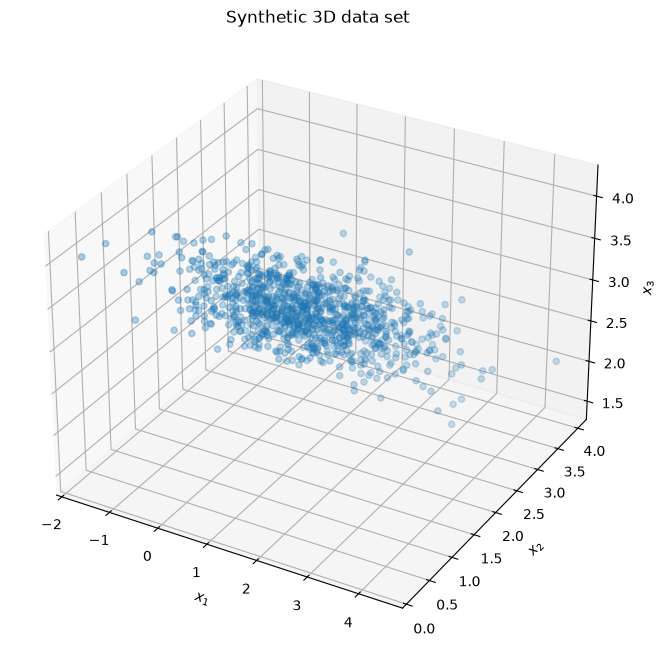

In [20]:
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], alpha=0.6)
ax.set_title('Synthetic 3D data set')
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_zlabel('$x_3$')
plt.show()

#### Classical PCA as a baseline

Before implementing pPCA, we apply classical PCA (slides 20–24) using `scikit-learn`. It finds the direction $\mathbf{u}_1$ of largest variance of the centered data, but it does not define a probability model: there is no likelihood $p(\mathbf{x})$, no noise model and no posterior $p(\mathbf{z} \mid \mathbf{x})$ (slide 26).

In [21]:
# center the data first
X_centered = X - np.mean(X, axis=0)

# apply classical PCA with m = 1 component
pca = PCA(n_components=m)
Z_pca = pca.fit_transform(X_centered)   # PCA representation z_i = U_m^T x_i of the centered data (one sample per row)

print("First principal direction u_1:", pca.components_[0])
print("Fraction of the variance explained by u_1:", pca.explained_variance_ratio_[0])

First principal direction u_1: [ 0.81092543  0.49583566 -0.31072004]
Fraction of the variance explained by u_1: 0.8891711992475331


#### 3a) Parameter estimation by maximum likelihood (3 pts)

Take the data matrix `X` from above and compute the maximum likelihood estimates $\hat{\boldsymbol{\mu}}$, $\hat\sigma^2$ and $\hat{\mathbf{W}}$ (with $\mathbf{R} = \mathbf{I}$) of the theorem on slide 38, using the eigenvalue decomposition of the empirical covariance matrix $\mathbf{S}$. Compare your estimates with the true parameters `mu_true`, `sigma_true` and `W_true` (code cell below) and interpret the result in the markdown cell that follows. In particular: why can $\hat{\mathbf{W}}$ differ from `W_true` even for a perfect fit, and how does $\hat{\mathbf{W}}$ relate to the first principal direction $\mathbf{u}_1$ of classical PCA?

*Hint: `np.linalg.eigh` returns the eigenvalues of a symmetric matrix in ascending order, whereas the lecture assumes $\lambda_1 \geq \cdots \geq \lambda_d$.*

In [22]:
########## YOUR SOLUTION HERE ##########

# Estimate the mean using one observation per row
mu_hat = X.mean(axis=0)

# Subtract the estimated mean from every observation
X_centered = X - mu_hat

# Use the maximum-likelihood covariance normalization 1/l, not 1/(l-1)
S = X_centered.T @ X_centered / X.shape[0]

# Compute the eigenvalues and orthonormal eigenvectors of the symmetric covariance
eigenvalues, eigenvectors = np.linalg.eigh(S)

# Obtain indices in descending eigenvalue order
order = np.argsort(eigenvalues)[::-1]

# Sort the eigenvalues from largest to smallest
eigenvalues = eigenvalues[order]

# Apply the same ordering to the eigenvector columns
eigenvectors = eigenvectors[:, order]

# Estimate the noise variance from the discarded eigenvalues
sigma2_hat = eigenvalues[m:].mean()

# Construct the loading matrix with R = I; clipping removes possible roundoff errors
W_hat = eigenvectors[:, :m] @ np.diag(np.sqrt(np.maximum(eigenvalues[:m] - sigma2_hat, 0.0)))

# Compare the estimated and generating means
print("Estimated / true mean:", mu_hat, mu_true)

# Compare variances with variances
print("Estimated / true noise variance:", sigma2_hat, sigma_true ** 2)

# Compare standard deviations with standard deviations
print("Estimated / true noise standard deviation:", np.sqrt(sigma2_hat), sigma_true)

# Display the estimated and generating loading matrices
print("Estimated W:\n", W_hat, "\nTrue W:\n", W_true)

# Quantify agreement of the principal directions independently of their signs
print("Absolute alignment with classical PCA:", abs(np.dot(W_hat[:, 0] / np.linalg.norm(W_hat[:, 0]), pca.components_[0])))


Estimated / true mean: [1.01547293 2.02239355 2.99595339] [1. 2. 3.]
Estimated / true noise variance: 0.06223377827461408 0.0625
Estimated / true noise standard deviation: 0.24946698834638237 0.25
Estimated W:
 [[-0.7846977 ]
 [-0.47979887]
 [ 0.30067044]] 
True W:
 [[ 0.8]
 [ 0.5]
 [-0.3]]
Absolute alignment with classical PCA: 0.9999999999999998


########## YOUR SOLUTION HERE ##########

In this run, the estimated mean is approximately $(1.01547,2.02239,2.99595)^\top$, the noise variance is $0.062234$ (true value $0.0625$), and the noise standard deviation is $0.249467$ (true value $0.25$). The estimated loading vector is approximately $(-0.78470,-0.47980,0.30067)^\top$, which is close to the negative of the generating vector.

The estimates of $\boldsymbol\mu$ and $\sigma^2$ should be close to the generating values $(1,2,3)^\top$ and $0.0625$, with sampling error because only 1000 observations are available. Compare $\sqrt{\hat\sigma^2}$ with sigma_true, which is a standard deviation.

The loading matrix is not identifiable: replacing $\mathbf W$ by $\mathbf W\mathbf R$ for an orthogonal $\mathbf R$ leaves $\mathbf W\mathbf W^\top$, and therefore the entire observed distribution, unchanged. For $m=1$, this means that $\mathbf W$ and $-\mathbf W$ are equally valid; an opposite sign does not indicate a bad fit. Finite-sample fluctuations can additionally change its length and direction slightly.

For $m=1$,
\(\hat{\mathbf W}=\mathbf u_1\sqrt{\lambda_1-\hat\sigma^2}.\)
Thus the loading vector is parallel to classical PCA's first principal direction, up to sign, but its length measures signal variation after subtracting the noise variance. scikit-learn uses $1/(l-1)$ for its reported eigenvalues, whereas our maximum-likelihood covariance uses $1/l$; this does not change the eigenvectors.

#### 3b) Visualizing the pPCA results (1 pt)

Now that you have estimated the parameters, visualize the result: project the data onto the principal subspace defined by $\hat{\mathbf{W}}$ and visually compare the projections with the original data.

Use your estimates $\hat{\mathbf{W}}$, $\hat{\boldsymbol{\mu}}$, $\hat\sigma^2$ and the posterior over the latent variables (slide 35),
\begin{align*}
    p(\mathbf{z}_i \mid \mathbf{x}_i) = \mathcal{N}\big(\mathbf{z}_i \mid \mathbf{M}^{-1} \mathbf{W}^\top (\mathbf{x}_i - \boldsymbol{\mu}),\, \sigma^2 \mathbf{M}^{-1}\big), \qquad \mathbf{M} = \mathbf{W}^\top \mathbf{W} + \sigma^2 \mathbf{I} \in \mathbb{R}^{m \times m}:
\end{align*}
encode every data point by its posterior mean $\hat{\mathbf{z}}_i = \mathbf{M}^{-1} \mathbf{W}^\top (\mathbf{x}_i - \boldsymbol{\mu})$ and map it back to the data space by $\hat{\mathbf{x}}_i = \mathbf{W} \hat{\mathbf{z}}_i + \boldsymbol{\mu}$ (the "reconstruction" of $\mathbf{x}_i$, which lies in the principal subspace).

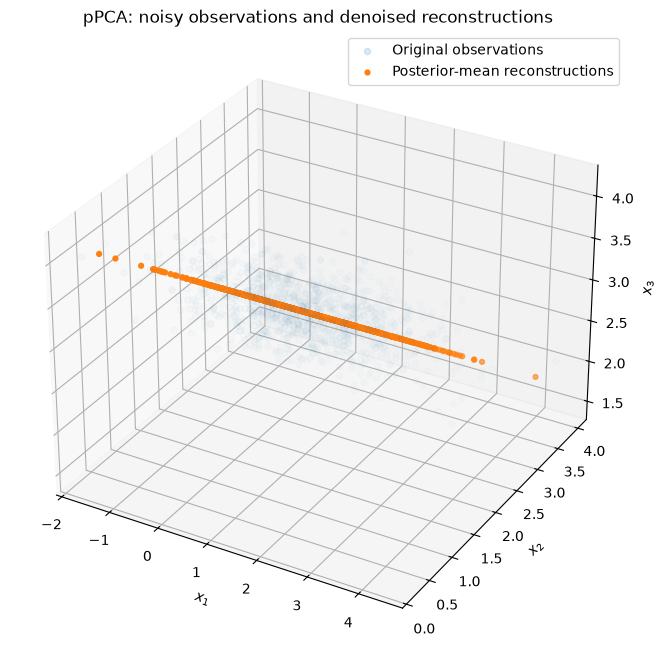

In [23]:
########## YOUR SOLUTION HERE ##########

# Form the latent-space matrix using the estimated parameters
M_hat = W_hat.T @ W_hat + sigma2_hat * np.eye(m)

# Solve for all posterior means and transpose back to one sample per row
Z_hat = np.linalg.solve(M_hat, W_hat.T @ (X - mu_hat).T).T

# Decode the posterior means without adding fresh observation noise
X_reconstructed = Z_hat @ W_hat.T + mu_hat

# Create a three-dimensional comparison plot
fig = plt.figure(figsize=(9, 8))
# Add a three-dimensional axis
ax = fig.add_subplot(111, projection='3d')
# Show the noisy observations with low opacity
ax.scatter(X[:, 0], X[:, 1], X[:, 2], alpha=0.15, label='Original observations')
# Show the reconstructions on the estimated affine principal line
ax.scatter(X_reconstructed[:, 0], X_reconstructed[:, 1], X_reconstructed[:, 2], s=12, label='Posterior-mean reconstructions')
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_zlabel('$x_3$')
ax.set_title('pPCA: noisy observations and denoised reconstructions')
ax.legend()
plt.show()


### Exercise 4: Probabilistic PCA on medical images (6 pts)

In this exercise we train and analyze a probabilistic PCA model on a set of [cine-MRI images](https://radiopaedia.org/articles/cine-imaging-mri). Our goal is dimensionality reduction: we compress the high-dimensional images into a low-dimensional (here: two-dimensional, $m = 2$) latent representation that still captures the key variations in the data.

We will analyze how the images are represented in the latent space and try to generate new images that look similar to the images in our data set.

#### Data background

The data set we are going to use for this exercise contains a sequence of $l = 450$ grayscale images of size $128 \times 128$ of a healthy test subject breathing normally. The images are taken in a sagittal plane where the lung, the diaphragm and the liver can be seen.

| Image taken during exhale  | Image taken during inhale | Anatomical labeling |
| :-: | :-: | :-: |
| <img src="lung_mri_1.jpg" alt="lung MRI" width="204">  | <img src="lung_mri_2.jpg" alt="lung MRI" width="200"> | <img src="lung_mri_detailed.jpg" alt="lung MRI" width="280"> |


#### Theoretical background

Let $\mathbf{x} \in \mathbb{R}^d$ represent a $128 \times 128$-pixel grayscale image, where $d = 128^2 = 16384$, and let $\mathbf{z} \in \mathbb{R}^m$ be an $m$-dimensional latent variable with $m < d$. We use probabilistic PCA (slide 27) as a model for dimensionality reduction and feature extraction:
\begin{align*}
    \mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}), \qquad \mathbf{x} \mid \mathbf{z} \sim \mathcal{N}(\mathbf{W}\mathbf{z} + \boldsymbol{\mu}, \sigma^2 \mathbf{I}),
\end{align*}
with parameters $\mathbf{W} \in \mathbb{R}^{d \times m}$, $\boldsymbol{\mu} \in \mathbb{R}^d$ and $\sigma^2 > 0$. By Exercise 1 (and slide 31) the marginal distribution of an image is
\begin{align*}
    p(\mathbf{x} \mid \mathbf{W}, \boldsymbol{\mu}, \sigma^2) = \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}, \mathbf{C}), \qquad \mathbf{C} = \mathbf{W}\mathbf{W}^\top + \sigma^2 \mathbf{I} \in \mathbb{R}^{d \times d},
\end{align*}
and the log-likelihood of the i.i.d. data set $\mathbf{X} = (\mathbf{x}_1, \ldots, \mathbf{x}_l)$ of $l = 450$ images is (Exercise 2)
\begin{align*}
    \log p(\mathbf{X} \mid \mathbf{W}, \boldsymbol{\mu}, \sigma^2) = -\frac{l}{2} \Big( d \log(2\pi) + \log|\mathbf{C}| \Big) - \frac12 \sum_{i=1}^l (\mathbf{x}_i - \boldsymbol{\mu})^\top \mathbf{C}^{-1} (\mathbf{x}_i - \boldsymbol{\mu}).
\end{align*}
In Exercise 3 we computed the maximum likelihood solution in closed form via the eigenvalue decomposition of $\mathbf{S}$. Here we take a different route and maximize the log-likelihood numerically by gradient-based optimization — the strategy we have to use for models without a closed-form solution.

#### Imports, data loading and plotting functions

In [24]:
# Imports. Nothing to do here, just run the cell
import os
import torch
import numpy as np
import SimpleITK as sitk
import pydicom
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from torch import optim
from typing import List, Dict

### install instructions SimpleITK https://simpleitk.readthedocs.io/en/master/gettingStarted.html
### install instructions pydicom https://pydicom.github.io/pydicom/stable/tutorials/installation.html

In [25]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# helper function to load the dicom data (nothing to do here)
def load_cine_mri_data(
    directory: str,
    verbose: bool = True,
) -> List[np.ndarray]:
    """
    Loads all DICOM images in `directory` and returns them as a list of 2D numpy arrays,
    sorted by their temporal position (i.e. in the order in which they were acquired).
    """

    def getDicomsInDirectory(
        directory: str,
    ) -> List[str]:
        """
            Get all dicom file inside directory by test reading them.
        """
        dicoms_files: List[str] = []
        try:
            # walk through the directory and all its subdirectories
            for root, _, entries in os.walk(directory):
                for entry in entries:
                    file_path = os.path.join(root, entry)
                    try:
                        ds: pydicom.FileDataset = pydicom.dcmread(file_path,
                                                                  stop_before_pixels=False)
                        if hasattr(ds, 'pixel_array'):
                            dicoms_files.append(file_path)
                    except:
                        pass
        except Exception as e:
            print(f"Failed to get dicoms in {directory}")
            raise e
        return dicoms_files

    def loadDicomMetaData(
        filepath: str,
    ) -> Dict[str, str]:
        reader = sitk.ImageFileReader()
        reader.SetFileName(filepath)
        reader.LoadPrivateTagsOn()
        reader.ReadImageInformation()

        dicom_metadata: Dict[str, str] = {}
        for k in reader.GetMetaDataKeys():
            v = reader.GetMetaData(k)
            dicom_metadata[k] = v
        return dicom_metadata

    def getTemporalPositionIdentifier(
        dicom_metadata: Dict[str, str],
    ) -> int:
        """
            Temporal position of the image in the sequence (DICOM tag 0020|0100).
        """
        value = -1
        try:
            value = int(dicom_metadata['0020|0100'])
        except:
            pass
        return value

    def loadDicom2D(
        filepath: str,
        output_pixel_type = sitk.sitkFloat32,
    ) -> sitk.Image:
        """
        """
        image = sitk.ReadImage(filepath, output_pixel_type)
        image = sitk.Extract(image,
                             (image.GetWidth(), image.GetHeight(), 0),
                             (0, 0, 0))
        return image

    if verbose:
        print("Loading images in:")
        print(f"    {directory}")

    if not os.path.isdir(directory):
        raise FileNotFoundError(f"The directory '{directory}' does not exist. Place the folder with the "
                                f"DICOM images next to this notebook or adapt the variable `directory`.")
    files = getDicomsInDirectory(directory)
    images_dict: Dict[int, sitk.Image] = {}

    if verbose:
        print(f"Found {len(files)} images.")
    if len(files) == 0:
        raise FileNotFoundError(f"No DICOM images found in '{directory}' (searched recursively). Check that the "
                                f"450 files 'Mag (0001)', ..., 'Mag (0450)' are in this folder.")

    for file in files:
        image = loadDicom2D(file)
        metadata = loadDicomMetaData(file)
        key = getTemporalPositionIdentifier(metadata)
        images_dict[key] = image

    # sort the images by their temporal position, so that consecutive entries are consecutive frames
    images_list: List[np.ndarray] = [sitk.GetArrayFromImage(images_dict[key]) for key in sorted(images_dict.keys())]

    if verbose:
        print("Finished loading images.")

    return images_list


In [26]:
def plot_encodings(encodings, with_color = False):
    """
    Scatter plot of 2D encodings; `encodings` has shape (number of images, 2), one image per row.
    """
    fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(15, 6))

    # plot encodings of training data
    if with_color:
        num_of_encodings = encodings.shape[0]
        base = plt.cm.winter
        cmap = ListedColormap(base(np.linspace(0, 1, num_of_encodings)))
        colors = list(range(0, num_of_encodings))
        scatter = axes.scatter(
            encodings[:, 0].cpu().detach().numpy(), encodings[:, 1].cpu().detach().numpy(),
            c=colors, cmap=cmap, alpha=0.7
        )

        cb = fig.colorbar(scatter, ticks=range(num_of_encodings))
        cb.ax.set_title("Image #")
        axes.set_title(f"2D color-coded encoding of the first {num_of_encodings} images")
    else:
        axes.scatter(
            encodings[:, 0].cpu().detach().numpy(), encodings[:, 1].cpu().detach().numpy(), alpha=0.7
        )
        axes.set_title("2D encoding of the data")
    axes.set_xticks([])
    axes.set_yticks([])
    axes.set_xlabel("$z_1$")
    axes.set_ylabel("$z_2$")

    return fig

In [27]:
### Make sure the images directory is in the correct relative location to the notebook interpreter

# loading the images
directory = "images"
image_arr = np.array(load_cine_mri_data(directory))   # shape (l, 128, 128)

# flatten the images into a matrix with one image (sample) per row: shape (l, d)
flattened = image_arr.reshape(-1, 128 * 128)
l = flattened.shape[0]

# preprocessing: center the data and scale it such that the average per-pixel variance is one
# (with standardized data the parameters W, mu and sigma^2 are of order one, which makes the
# gradient-based optimization below with a fixed learning rate well-behaved)
data_mean = flattened.mean(axis=0)               # mean image
data_scale = (flattened - data_mean).std()       # global standard deviation of the centered pixel values
X_train = (flattened - data_mean) / data_scale   # shape (l, d)

# creating the dataloader for the later training (full batch: all l = 450 images in one batch)
image_data = torch.utils.data.DataLoader(
    X_train.astype(np.double), batch_size=l, shuffle=True
)

Loading images in:
    images
Found 450 images.
Finished loading images.


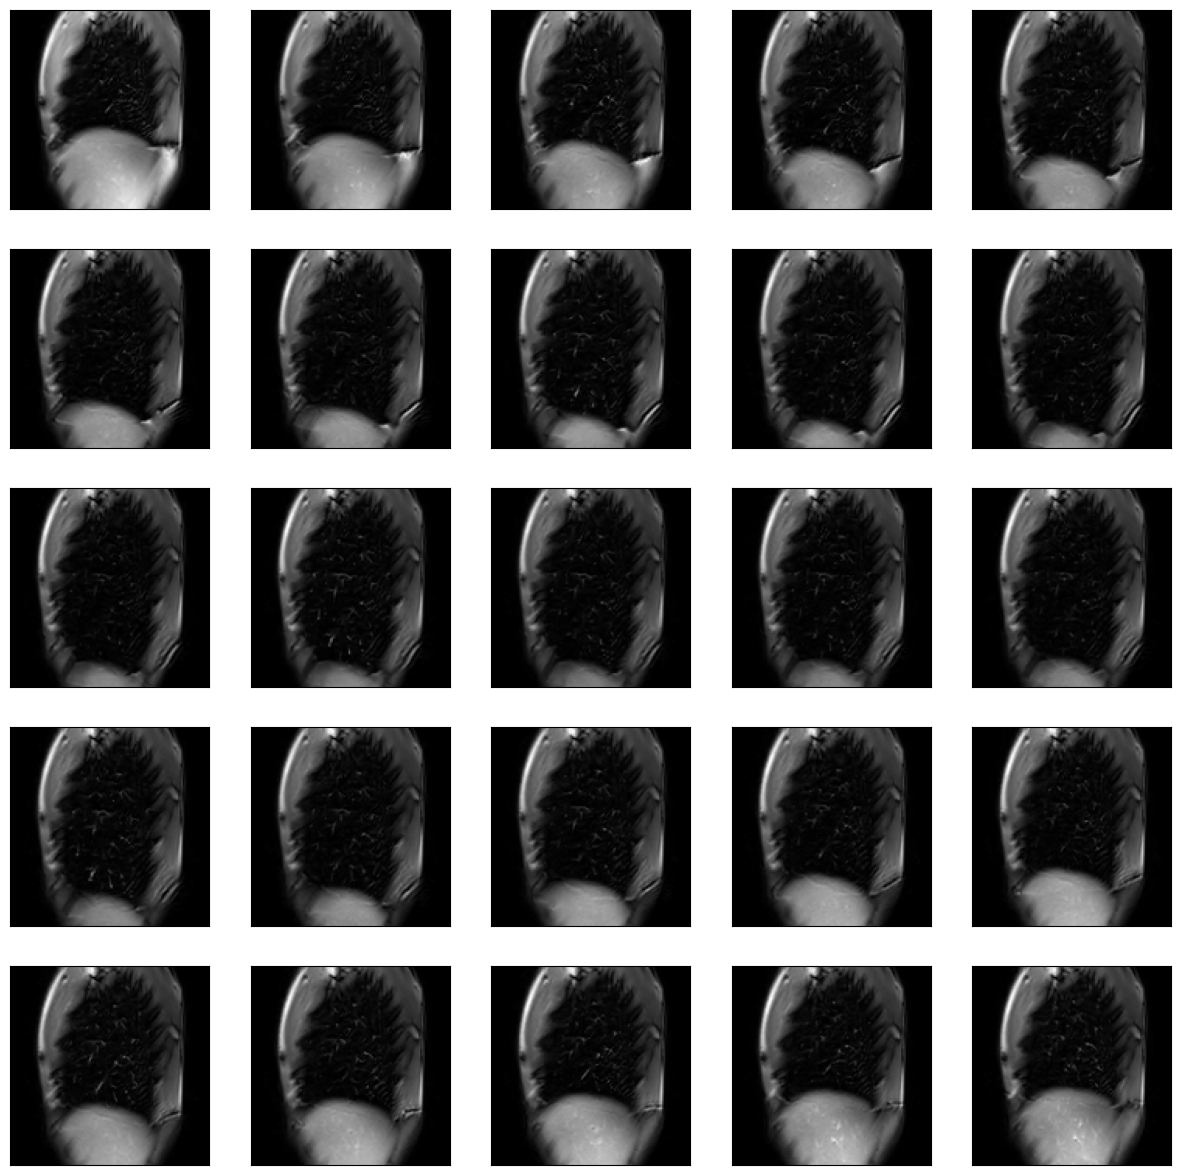

In [28]:
# nothing to do here, just run the cell
# plot first 25 images (consecutive frames of the breathing sequence)
fig, axes = plt.subplots(nrows=5, ncols=5, figsize=(15, 15))
for image, ax in zip(image_arr, axes.flat):
        ax.set_xticks(())
        ax.set_yticks(())
        ax.grid(False)
        ax.imshow(image.reshape(128, 128), cmap='gray')
plt.show()

#### 4a) The cost function (2 pts)

Since the log-likelihood is differentiable with respect to the parameters, we optimize the parameters with gradient descent. We minimize the cost function
\begin{align*}
    J(\mathbf{W}, \boldsymbol{\mu}, \sigma^2) = \log|\mathbf{C}| + \frac{1}{l} \sum_{i=1}^l (\mathbf{x}_i - \boldsymbol{\mu})^\top \mathbf{C}^{-1} (\mathbf{x}_i - \boldsymbol{\mu}),
\end{align*}
which is the negative log-likelihood $-\log p(\mathbf{X} \mid \mathbf{W}, \boldsymbol{\mu}, \sigma^2)$ divided by $l / 2$ and without the additive constant $d \log(2\pi)$. Minimizing $J$ is therefore equivalent to maximizing the log-likelihood.

It is computationally much cheaper to work with the $m \times m$ matrix
\begin{align*}
    \mathbf{M} = \mathbf{W}^\top \mathbf{W} + \sigma^2 \mathbf{I} \in \mathbb{R}^{m \times m}
\end{align*}
known from the posterior (slide 35) than with the $d \times d$ matrix $\mathbf{C}$ (here $16384 \times 16384$). Exploiting the special structure of $\mathbf{C}$, the [matrix determinant lemma](https://en.wikipedia.org/wiki/Matrix_determinant_lemma#Generalization) and the [Woodbury matrix identity](https://en.wikipedia.org/wiki/Woodbury_matrix_identity) show that
\begin{align*}
    J(\mathbf{W}, \boldsymbol{\mu}, \sigma^2) = (d - m) \log \sigma^2 + \log|\mathbf{M}| + \frac{1}{l\, \sigma^2} \sum_{i=1}^l \Big( \|\mathbf{x}_i - \boldsymbol{\mu}\|_2^2 - (\mathbf{x}_i - \boldsymbol{\mu})^\top \mathbf{W} \mathbf{M}^{-1} \mathbf{W}^\top (\mathbf{x}_i - \boldsymbol{\mu}) \Big).
\end{align*}
Here we consider $m = 2$, i.e. $\mathbf{z}$ is two-dimensional. We start by implementing the cost function.

The following Python function `cost_function` evaluates the cost function $J$ for a data set stored as a matrix with one sample per row,
\begin{equation*}
\texttt{X} = \begin{bmatrix} \mathbf{x}_1^\top \\ \vdots \\ \mathbf{x}_l^\top \end{bmatrix} \in \mathbb{R}^{l \times d}
\end{equation*}
(i.e. $\mathbf{X}^\top$ in lecture notation), and parameters $\mathbf{W}$, $\boldsymbol{\mu}$ and $\log \sigma^2$. To enforce $\sigma^2 > 0$, we optimize the real-valued parameter $\log \sigma^2$ instead of $\sigma^2$. Read through and try to understand the existing implementation. Add a final line to the function that computes and returns the value of the cost function by making use of the already computed values and matrices.

*Note: the sum in $J$ is divided by the number $l$ of samples in `X` (`X.shape[0]`, which is $4$ in the sanity check below and $450$ during training), not by a fixed constant.*

In [31]:
d = 128 * 128   # dimension of the data (number of pixels)
m = 2           # dimension of the latent space

def cost_function(X, W, mu, logsigma2):
    """
    Cost function J (negative log-likelihood of the pPCA model, scaled and without constants).

    Args
    ----
    X : torch.Tensor, shape (l, d) or (l, 128, 128)
        Batch of l images (one sample per row); if not already flat, the function flattens it to (l, d).
    W : torch.Tensor, shape (d, m)
        Loading matrix W.
    mu : torch.Tensor, shape (1, d)
        Mean vector mu (as a row vector, broadcast against the rows of X).
    logsigma2 : torch.Tensor, shape (1,)
        Logarithm of the isotropic noise variance, sigma^2 = exp(logsigma2).

    Returns
    -------
    j : torch.Tensor, shape (1,)
        The value of the cost function J. Lower is better.
    """
    # flatten the data into a matrix with d = 128 * 128 = 16384 columns; l = number of samples in the batch
    X = X.view(-1, d)
    l = X.shape[0]

    # matrix Xshifted with rows (x_i - mu)^T
    # note: mu is defined as a row vector
    Xshifted = X - mu

    # matrix Y with rows (x_i - mu)^T W
    Y = Xshifted @ W

    # matrix M = W^T W + sigma^2 I  (m x m)
    sigma2 = logsigma2.exp()
    M = W.T @ W + sigma2 * torch.eye(m, dtype=W.dtype, device=W.device)

    # log-determinant of M
    Mlogdet = M.logdet()

    # inverse of M
    Minverse = M.inverse()

    # vector v with v[i] = (x_i - mu)^T W M^{-1} W^T (x_i - mu)
    v = (Y @ Minverse @ Y.T).diagonal()

    # sum_i ( ||x_i - mu||^2 - v[i] )
    summed = (Xshifted.pow(2).sum(dim=1) - v).sum()

    ########## YOUR SOLUTION HERE ##########
    
    # Combine the log-determinant and the sample-averaged quadratic term.
    j = (d - m) * logsigma2 + Mlogdet + summed / (l * sigma2)

    # Return the differentiable objective for backpropagation.
    return j


In [32]:
# sanity check (nothing to do here, just run the cell)
torch.manual_seed(0)
test_X = torch.randn((4, 128, 128), dtype=torch.float64)       # l = 4 random test "images"
test_W = torch.randn((128 * 128, 2), dtype=torch.float64)
test_mu = torch.zeros(1, 128 * 128, dtype=torch.float64)
test_logsigma2 = torch.zeros(1, dtype=torch.float64)

test_cost = cost_function(test_X, test_W, test_mu, test_logsigma2)

assert abs(test_cost.item() - 16516.6714) < 1e-3, f"Unexpected cost function result: {test_cost.item()}"
print(f"Cost function on the test data: {test_cost.item():.4f} (expected: 16516.6714)")

Cost function on the test data: 16516.6714 (expected: 16516.6714)


#### Training

Now that the cost function is implemented, we can train the probabilistic PCA model by minimizing $J$ with respect to $\mathbf{W}$, $\boldsymbol{\mu}$ and $\log \sigma^2$ using gradient-based optimization (Adam). Since we have only $l = 450$ images, which all fit into one batch, every epoch consists of a single gradient step, and we need a large number of epochs for a proper optimization of the parameters. The cell runs for about 2–3 minutes on a laptop CPU.

In [33]:
# nothing to do here, just run the cell
torch.manual_seed(0)
W = torch.randn((d, m), device=device, requires_grad=True, dtype=torch.float64)
mu = torch.zeros(1, d, device=device, requires_grad=True, dtype=torch.float64)
logsigma2 = torch.zeros(1, device=device, requires_grad=True, dtype=torch.float64)

# define the optimizer
optimizer = optim.Adam([W, mu, logsigma2], lr=0.01)

# track the training loss
training_loss = []

# optimize parameters for 800 epochs
for i in range(800):
    # for each minibatch (here: one batch with all l = 450 images)
    for batch_X in image_data:
        # move batch to the GPU if available
        batch_X = batch_X.to(device)

        # reset the gradient information
        optimizer.zero_grad()

        # evaluate the cost function on the training data set
        loss = cost_function(batch_X, W, mu, logsigma2)

        # update the statistics
        training_loss.append(loss.item())

        # perform backpropagation
        loss.backward()

        # perform a gradient descent step
        optimizer.step()

    if i % 50 == 0 or i == 799:
        print(f"Epoch {i + 1:3d}: training loss (cost function): {training_loss[-1]:10.3f}   sigma^2 = {logsigma2.exp().item():.4f}")

Epoch   1: training loss (cost function):  16402.419   sigma^2 = 1.0101
Epoch  51: training loss (cost function):  13868.993   sigma^2 = 0.8524
Epoch 101: training loss (cost function):   3620.550   sigma^2 = 0.4553
Epoch 151: training loss (cost function):   -382.295   sigma^2 = 0.3586
Epoch 201: training loss (cost function):   -832.841   sigma^2 = 0.3491
Epoch 251: training loss (cost function):  -1053.308   sigma^2 = 0.3445
Epoch 301: training loss (cost function):  -1341.194   sigma^2 = 0.3384
Epoch 351: training loss (cost function):  -1817.498   sigma^2 = 0.3286
Epoch 401: training loss (cost function):  -3159.675   sigma^2 = 0.3024
Epoch 451: training loss (cost function):  -6363.059   sigma^2 = 0.2484
Epoch 501: training loss (cost function):  -8218.389   sigma^2 = 0.2223
Epoch 551: training loss (cost function):  -8585.684   sigma^2 = 0.2175
Epoch 601: training loss (cost function):  -8651.422   sigma^2 = 0.2167
Epoch 651: training loss (cost function):  -8667.236   sigma^2 =

#### 4b) Encodings (2 pts)

Remember that the posterior distribution of the latent representation $\mathbf{z}$ given an image $\mathbf{x}$ is also Gaussian (slide 35):
\begin{align*}
    p(\mathbf{z} \mid \mathbf{x}) = \mathcal{N}\big(\mathbf{z} \mid \mathbf{M}^{-1} \mathbf{W}^\top (\mathbf{x} - \boldsymbol{\mu}),\, \sigma^2 \mathbf{M}^{-1}\big), \qquad \mathbf{M} = \mathbf{W}^\top \mathbf{W} + \sigma^2 \mathbf{I} \in \mathbb{R}^{2 \times 2}.
\end{align*}
We use this result to encode the images in the lower-dimensional latent space. In contrast to classical PCA there is not one unique representation of an image in the latent space; instead, each image gives rise to a whole distribution over representations, whose covariance matrix $\sigma^2 \mathbf{M}^{-1}$ quantifies the uncertainty of the representation. Here we use the posterior mean
\begin{align*}
    \mathbb{E}[\mathbf{z} \mid \mathbf{x}] = \mathbf{M}^{-1} \mathbf{W}^\top (\mathbf{x} - \boldsymbol{\mu})
\end{align*}
as the encoding of $\mathbf{x}$. Alternatively, one could sample from the posterior.

Compute the encodings of all $l = 450$ training images with the trained parameters `W`, `mu` and `logsigma2` and store them in the variable `image_encodings` as a matrix of shape $(m, l) = (2, 450)$, i.e. as $\mathbf{Z} = (\mathbf{z}_1, \ldots, \mathbf{z}_l)$ in lecture notation (slide 24) with one image per column.

In [34]:
# the (standardized) data matrix in lecture layout: X = (x_1, ..., x_l) of shape (d, l), one image per column
X = torch.from_numpy(X_train).to(device).T
mu_t = mu.T   # mu as a column vector of shape (d, 1)

In [35]:
########## YOUR SOLUTION HERE ##########

# Disable gradient tracking because encoding does not update the trained parameters
with torch.no_grad():
    # Form the 2 x 2 posterior matrix on the same device and with the same dtype as W.
    M = W.T @ W + logsigma2.exp() * torch.eye(W.shape[1], dtype=W.dtype, device=W.device)
    # Solve M Z = W^T (X - mu) to obtain one encoding per column.
    image_encodings = torch.linalg.solve(M, W.T @ (X - mu_t))

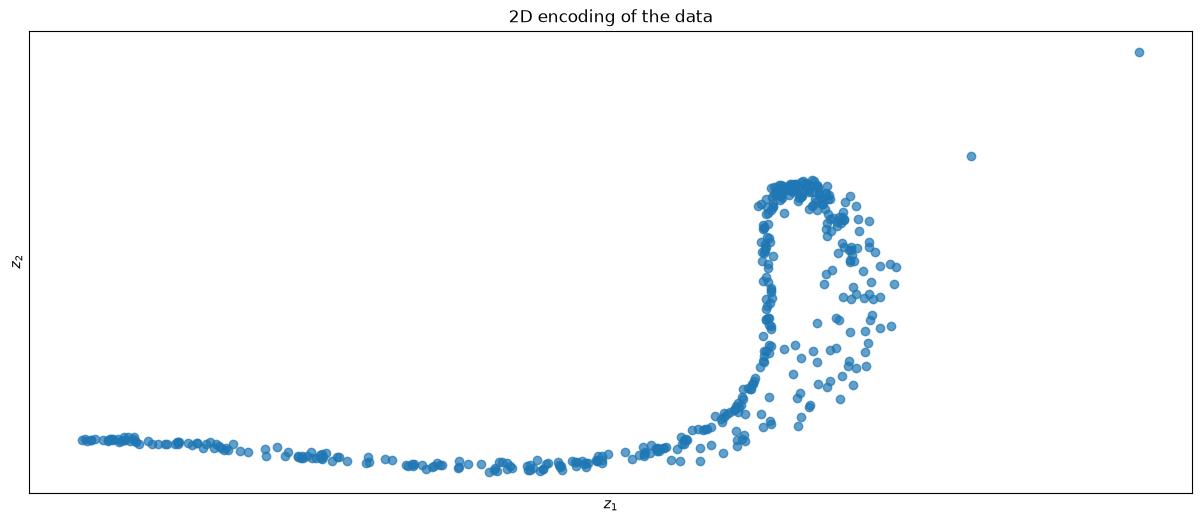

In [36]:
# plot the encodings
# nothing to do here, just run the cell
plot_encodings(image_encodings.T)
plt.show()

It is easier to see a pattern if we know which image is projected where.

<i>Run the code below to get a color-coded plot of the encodings of the first 25 images (consecutive frames of the breathing sequence). Do you see the pattern now?</i>

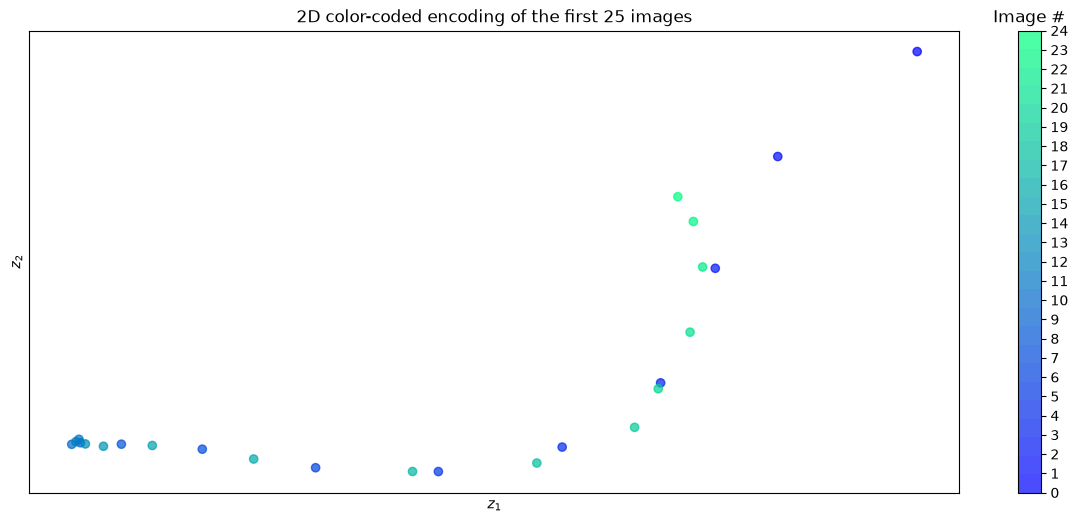

In [37]:
# color plot the encodings of the first 25 images
# nothing to do here, just run the cell
plot_encodings(image_encodings.T[:25], with_color=True)
plt.show()

Try to interpret your results. Do you see any pattern that could be explained by the images we encoded? (Answer briefly in 2 or 3 sentences.)

########## YOUR SOLUTION HERE ##########

The first 25 color-coded encodings form a curved, approximately U-shaped trajectory, with several frames clustered near the left end and other frames returning along similar parts of the curve. This is consistent with gradual changes during inhalation and exhalation and with similar images at recurring breathing phases. The trajectory is not a perfect closed circle: breathing varies, and a linear two-dimensional model cannot represent every detail of the motion.

#### 4c) Generating new images (2 pts)

Probabilistic PCA is a <i>generative model</i> (slide 28): once the parameters $\mathbf{W}, \boldsymbol{\mu}$ and $\sigma^2$ are learned, we can synthesize new data points from the model distribution. Specifically, we first sample a latent variable
\begin{align*}
    \mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})
\end{align*}
and then generate a corresponding data sample by decoding it through the model (slide 27):
\begin{align*}
    \mathbf{x} = \mathbf{W} \mathbf{z} + \boldsymbol{\mu} + \boldsymbol{\varepsilon}, \qquad \boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{I}).
\end{align*}
Implement the function `sample_ppca` and sample new images from your model.

In [38]:
########## YOUR SOLUTION HERE ##########
# @torch.no_grad()
# def sample_ppca(W, mu, logsigma2, n_samples=16):
#     """
#     Generate new samples from a trained probabilistic PCA model:
#         z   ~ N(0, I_m)
#         eps ~ N(0, sigma^2 I_d)
#         x   = W z + mu + eps
#
#     Args:
#         W          : (d, m) torch.Tensor - loading matrix
#         mu         : (1, d) torch.Tensor - mean in data space
#         logsigma2  : (1,)   torch.Tensor - log noise variance
#         n_samples  : int - number of new samples to generate
#
#     Returns:
#         X_samples  : (n_samples, d) torch.FloatTensor - generated samples, one sample per row
#     """
#
#     # sample latent variables and isotropic noise
#
#     # generate new data samples x = W z + mu + eps (one sample per row)


# Generate samples without retaining an autograd graph
@torch.no_grad()

# Accept the trained parameters and the requested number of images
def sample_ppca(W, mu, logsigma2, n_samples=16):
    """Return samples of shape (n_samples, d) from the learned pPCA distribution."""

    # Draw independent standard-normal latent vectors with matching dtype and device
    z = torch.randn(n_samples, W.shape[1], dtype=W.dtype, device=W.device)

    # Convert the log variance to the noise standard deviation and draw independent noise
    eps = torch.exp(0.5 * logsigma2) * torch.randn(n_samples, W.shape[0], dtype=W.dtype, device=W.device)

    # Decode each latent vector, add the learned mean, and add observation noise
    return z @ W.T + mu + eps

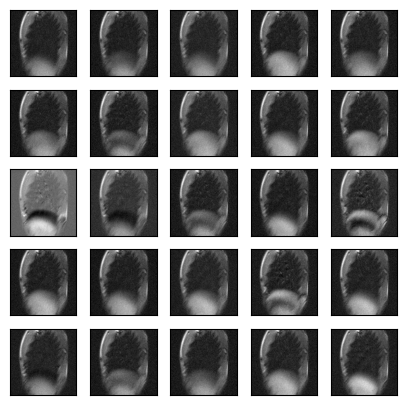

In [39]:
# nothing to do here, just run the cell
# generate the new samples
torch.manual_seed(1)
X_new = sample_ppca(W, mu, logsigma2, n_samples=25).cpu()

# undo the standardization of the original data
X_new = X_new.numpy() * data_scale + data_mean

fig, axes = plt.subplots(nrows=5, ncols=5, figsize=(5, 5))
for image, ax in zip(X_new, axes.flat):
        ax.set_xticks(())
        ax.set_yticks(())
        ax.grid(False)
        ax.imshow(image.reshape(128, 128), cmap='gray')

plt.show()

What observations can you make about the generated images? Do they closely resemble the original ones, or do you notice any artifacts or differences? How might we further improve the generation quality? (Answer in a few sentences.)

########## YOUR SOLUTION HERE ##########

The generated images retain the broad anatomical layout, including the dark lung region and the bright lower boundary, but they are blurry and show grain and some doubled or smeared boundaries. A two-dimensional linear representation cannot capture all fine details or nonlinear breathing motion, and independent isotropic Gaussian observation noise adds grain; latent samples far from the observed encodings may also produce implausible patterns. Quality could improve by increasing the latent dimension (selected on held-out data), using a richer noise model, or learning a nonlinear generative model; displaying the noiseless decoder mean removes grain but is no longer a full sample from the fitted observation distribution.